# 🎗️ Breast Cancer Diagnostics with Supervised Machine Learning

This notebook demonstrates a rigorous end-to-end pipeline for classifying breast cancer tumors as **Malignant (1)** or **Benign (0)** using the UCI Breast Cancer Wisconsin dataset. We perform exploratory data analysis, scale features correctly to avoid data leakage, and train and compare seven different machine learning architectures across two distinct feature configurations (10 mean features vs. all 30 features).

In [ ]:
import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec # subplots

import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone

import warnings
import kagglehub
from kagglehub import KaggleDatasetAdapter

## 📥 Step 1: Data Acquisition & Preprocessing

We load the dataset using `kagglehub` and remove redundant features such as unique identifiers (`id`) and empty helper columns to prepare the raw values for clean analysis.

In [ ]:
df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS,"uciml/breast-cancer-wisconsin-data","data.csv")
df.head()

100%|██████████| 122k/122k [00:00<00:00, 25.8MB/s]


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [ ]:
df.drop('id',axis=1,inplace=True)
df.drop('Unnamed: 32',axis=1,inplace=True)
#len(df)
df.shape

(569, 31)

In [ ]:
df.diagnosis.unique()

array(['M', 'B'], dtype=object)

### Target Representation
To prepare the dataset for binary classification, we map the diagnostic classes (`'M'` for malignant and `'B'` for benign) to numerical formats (`1` and `0`).

In [ ]:
df['diagnosis'] = df['diagnosis'].map({'M':1,'B':0})
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 📊 Step 2: Exploratory Data Analysis (EDA)

We inspect the class balance of our targets and visualize the distribution of our primary 10 mean features to see how well they separate malignant cases from benign ones.

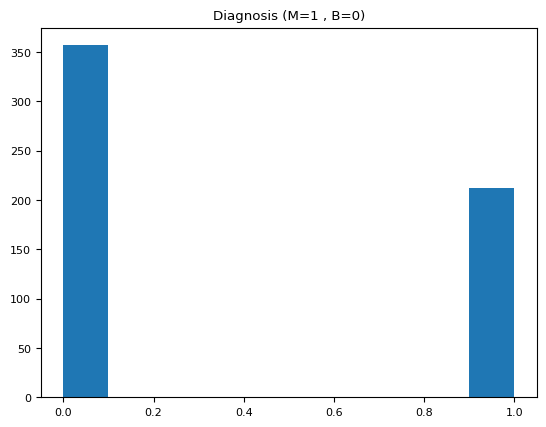

In [ ]:
plt.hist(df['diagnosis'])
plt.title('Diagnosis (M=1 , B=0)')
plt.show()

In [ ]:
features_mean=list(df.columns[1:11])
# split dataframe into two based on diagnosis
dfM=df[df['diagnosis'] ==1]
dfB=df[df['diagnosis'] ==0]

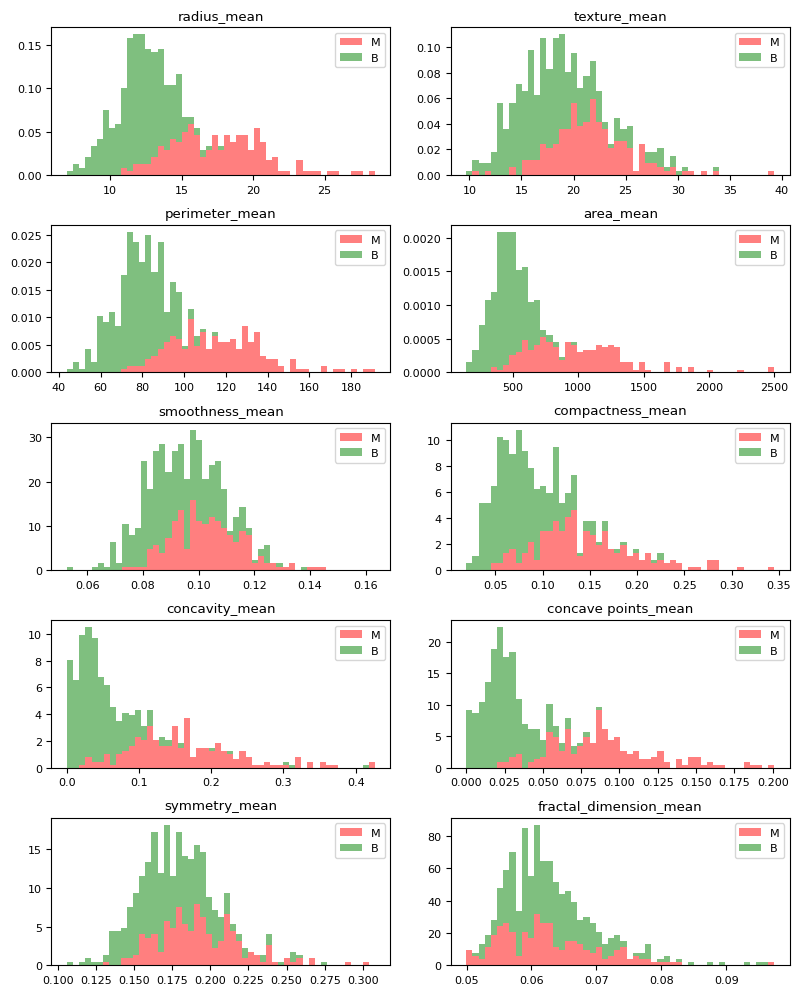

In [ ]:
#Stack the data
plt.rcParams.update({'font.size': 8})
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(8,10))
axes = axes.ravel()
for idx,ax in enumerate(axes):
    ax.figure
    binwidth= (max(df[features_mean[idx]]) - min(df[features_mean[idx]]))/50
    ax.hist([dfM[features_mean[idx]],dfB[features_mean[idx]]], bins=np.arange(min(df[features_mean[idx]]), max(df[features_mean[idx]]) + binwidth, binwidth) , alpha=0.5,stacked=True, density = True, label=['M','B'],color=['r','g'])
    ax.legend(loc='upper right')
    ax.set_title(features_mean[idx])
plt.tight_layout()
plt.show()

## ⚙️ Step 3: Feature Engineering & Train-Test Splitting

To ensure our model generalizations are scientifically sound, we perform train-test splits before running any scaling algorithms. This fully prevents **data leakage**.

### Step 3-1: Split into Features (X) and Target (y)
We will use the 10 mean characteristics (`features_mean`) as our feature set `X`, and the `diagnosis` column as our target variable `y`.

In [ ]:
X = df[features_mean]
y = df['diagnosis']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (569, 10)
Target (y) shape: (569,)


### Step 3-2: Train-Test Split
We split the data first (e.g., 70% train, 30% test) to prevent any data leakage during scaling.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Training set size: 398 samples
Test set size: 171 samples


### Step 3-3: Standardize the Features
We fit the `StandardScaler` only on the training set (`X_train`) and use it to transform both the training and testing sets.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Only transform the test data
X_test_scaled = scaler.transform(X_test)

print("Scaled sample from training set:\n", X_train_scaled[0])

Scaled sample from training set:
 [1.70581999 1.04974466 2.12129465 1.66933676 2.27645789 4.54429486
 3.53913939 2.84839268 4.03238962 2.63977264]


### Feature Scaling & Normalization

Many distance-based and gradient-descent-based models (like KNN, SVM, Logistic Regression, and MLPs) require features to be on a uniform scale. We apply `StandardScaler` fitted exclusively on our training partitions.

### Alternative: Using All 30 Features
Here we split the dataset using all available features (excluding only the target column `diagnosis`) as suggested, scale them, and split them into training and testing sets.

In [ ]:
# Extract all features and the target
X_all = df.drop('diagnosis', axis=1)
y = df['diagnosis']

# Train-Test Split
X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all, y, test_size=0.3, random_state=42, stratify=y
)

# Standardize all features
scaler_all = StandardScaler()
X_train_all_scaled = scaler_all.fit_transform(X_train_all)
X_test_all_scaled = scaler_all.transform(X_test_all)

print("Using ALL features:")
print("X_train_all_scaled shape:", X_train_all_scaled.shape)
print("X_test_all_scaled shape:", X_test_all_scaled.shape)

Using ALL features:
X_train_all_scaled shape: (398, 30)
X_test_all_scaled shape: (171, 30)


### Step 4: Compare Supervised Learning Algorithms
We will define, train, and evaluate the 7 algorithms on both our 10-feature scaled dataset and our 30-feature scaled dataset.

In [ ]:

# Define the uniform random state
RANDOM_STATE = 42

# Initialize all 7 models
models = {
    'Naive Bayes': GaussianNB(),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'SVM': SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'ANN': MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=1500,
        early_stopping=True,
        random_state=RANDOM_STATE
    )
}

# 5-Fold Stratified Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

# Tree-based models do not require feature scaling
tree_models = [
    'Decision Tree',
    'Random Forest'
]

results = []
trained_models = {}

# Evaluate each model on both feature configurations
for name, model in models.items():

    trained_models[name] = {}

    # Choose scaler
    #scaler = 'passthrough' if name in tree_models else StandardScaler()

    # -----------------------------------
    # 1. 10 Features (Mean Only)
    # -----------------------------------

    pipeline_10 = Pipeline([
        ('scaler', 'passthrough' if name in tree_models else StandardScaler()),
        ('classifier', clone(model))
    ])

    # Cross Validation on training data
    cv_10 = cross_validate(
        pipeline_10,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    # Train final model on the complete training set
    pipeline_10.fit(X_train, y_train)

    preds_10 = pipeline_10.predict(X_test)
    probs_10 = pipeline_10.predict_proba(X_test)[:, 1]

    # Test set metrics
    acc_10 = accuracy_score(y_test, preds_10)
    prec_10 = precision_score(y_test, preds_10, zero_division=0)
    rec_10 = recall_score(y_test, preds_10, zero_division=0)
    f1_10 = f1_score(y_test, preds_10, zero_division=0)
    auc_10 = roc_auc_score(y_test, probs_10)

    # -----------------------------------
    # 2. 30 Features (All)
    # -----------------------------------

    pipeline_30 = Pipeline([
        ('scaler', 'passthrough' if name in tree_models else StandardScaler()),
        ('classifier', clone(model))
    ])

    # Cross Validation on training data
    cv_30 = cross_validate(
        pipeline_30,
        X_train_all,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    # Train final model on the complete training set
    pipeline_30.fit(X_train_all, y_train)

    preds_30 = pipeline_30.predict(X_test_all)
    probs_30 = pipeline_30.predict_proba(X_test_all)[:, 1]

    # Test set metrics
    acc_30 = accuracy_score(y_test, preds_30)
    prec_30 = precision_score(y_test, preds_30, zero_division=0)
    rec_30 = recall_score(y_test, preds_30, zero_division=0)
    f1_30 = f1_score(y_test, preds_30, zero_division=0)
    auc_30 = roc_auc_score(y_test, probs_30)

    # Store all results
    results.append({
        'Model': name,

        '10-Feat Accuracy': acc_10,
        '10-Feat Precision': prec_10,
        '10-Feat Recall': rec_10,
        '10-Feat F1': f1_10,
        '10-Feat ROC-AUC': auc_10,

        '10-Feat CV Accuracy': cv_10['test_accuracy'].mean(),
        '10-Feat CV Precision': cv_10['test_precision'].mean(),
        '10-Feat CV Recall': cv_10['test_recall'].mean(),
        '10-Feat CV F1': cv_10['test_f1'].mean(),
        '10-Feat CV ROC-AUC': cv_10['test_roc_auc'].mean(),
        '10-Feat CV Recall Std': cv_10['test_recall'].std(),

        '30-Feat Accuracy': acc_30,
        '30-Feat Precision': prec_30,
        '30-Feat Recall': rec_30,
        '30-Feat F1': f1_30,
        '30-Feat ROC-AUC': auc_30,

        '30-Feat CV Accuracy': cv_30['test_accuracy'].mean(),
        '30-Feat CV Precision': cv_30['test_precision'].mean(),
        '30-Feat CV Recall': cv_30['test_recall'].mean(),
        '30-Feat CV F1': cv_30['test_f1'].mean(),
        '30-Feat CV ROC-AUC': cv_30['test_roc_auc'].mean(),
        '30-Feat CV Recall Std': cv_30['test_recall'].std()
    })

    # Save both trained models separately
    trained_models[name]['10 Features'] = pipeline_10
    trained_models[name]['30 Features'] = pipeline_30


# Convert results into a DataFrame
df_results = pd.DataFrame(results)

# Display results sorted by 30-feature test accuracy
display(
    df_results.sort_values(
        by='30-Feat Accuracy',
        ascending=False
    ).style.format({
        col: '{:.2%}'
        for col in df_results.columns
        if col != 'Model'
    })
)


,Model,10-Feat Accuracy,10-Feat Precision,10-Feat Recall,10-Feat F1,10-Feat ROC-AUC,10-Feat CV Accuracy,10-Feat CV Precision,10-Feat CV Recall,10-Feat CV F1,10-Feat CV ROC-AUC,10-Feat CV Recall Std,30-Feat Accuracy,30-Feat Precision,30-Feat Recall,30-Feat F1,30-Feat ROC-AUC,30-Feat CV Accuracy,30-Feat CV Precision,30-Feat CV Recall,30-Feat CV F1,30-Feat CV ROC-AUC,30-Feat CV Recall Std
5,Logistic Regression,94.15%,92.19%,92.19%,92.19%,98.77%,93.22%,93.33%,88.51%,90.70%,98.54%,3.52%,97.08%,98.36%,93.75%,96.00%,99.75%,98.24%,100.00%,95.26%,97.57%,99.26%,1.67%
3,Random Forest,94.15%,93.55%,90.62%,92.06%,98.53%,92.72%,90.48%,91.20%,90.43%,97.78%,5.06%,96.49%,100.00%,90.62%,95.08%,99.68%,93.96%,92.59%,91.82%,91.91%,98.34%,6.01%
1,KNN,95.32%,95.16%,92.19%,93.65%,98.32%,94.47%,93.48%,91.86%,92.54%,96.92%,2.83%,96.49%,100.00%,90.62%,95.08%,98.82%,95.97%,98.51%,90.46%,94.25%,98.38%,5.15%
4,SVM,95.32%,98.28%,89.06%,93.44%,98.89%,93.22%,94.99%,87.15%,90.61%,98.45%,3.96%,95.91%,100.00%,89.06%,94.21%,99.72%,97.23%,97.87%,94.55%,96.15%,99.29%,4.17%
0,Naive Bayes,90.64%,91.38%,82.81%,86.89%,98.00%,90.96%,89.14%,87.15%,87.88%,97.19%,3.36%,93.57%,94.92%,87.50%,91.06%,99.33%,92.95%,91.19%,89.79%,90.42%,98.57%,5.83%
6,ANN,94.15%,93.55%,90.62%,92.06%,98.64%,92.71%,89.25%,92.55%,90.58%,98.30%,5.00%,91.81%,98.08%,79.69%,87.93%,99.37%,92.70%,94.05%,85.72%,89.64%,98.21%,6.05%
2,Decision Tree,91.81%,90.32%,87.50%,88.89%,94.12%,91.97%,88.88%,90.55%,89.51%,92.03%,2.47%,90.64%,96.15%,78.12%,86.21%,92.22%,91.70%,90.94%,86.41%,88.40%,89.12%,7.90%


### Step 6: Detailed 2x7 Grid Performance Visualization (Accuracy vs. Recall)
As observed, **Recall** is clinically the most vital metric here. Let's build a comprehensive 2x7 layout comparing **Accuracy, Recall, and F1-Score** for each model across both feature sizes.

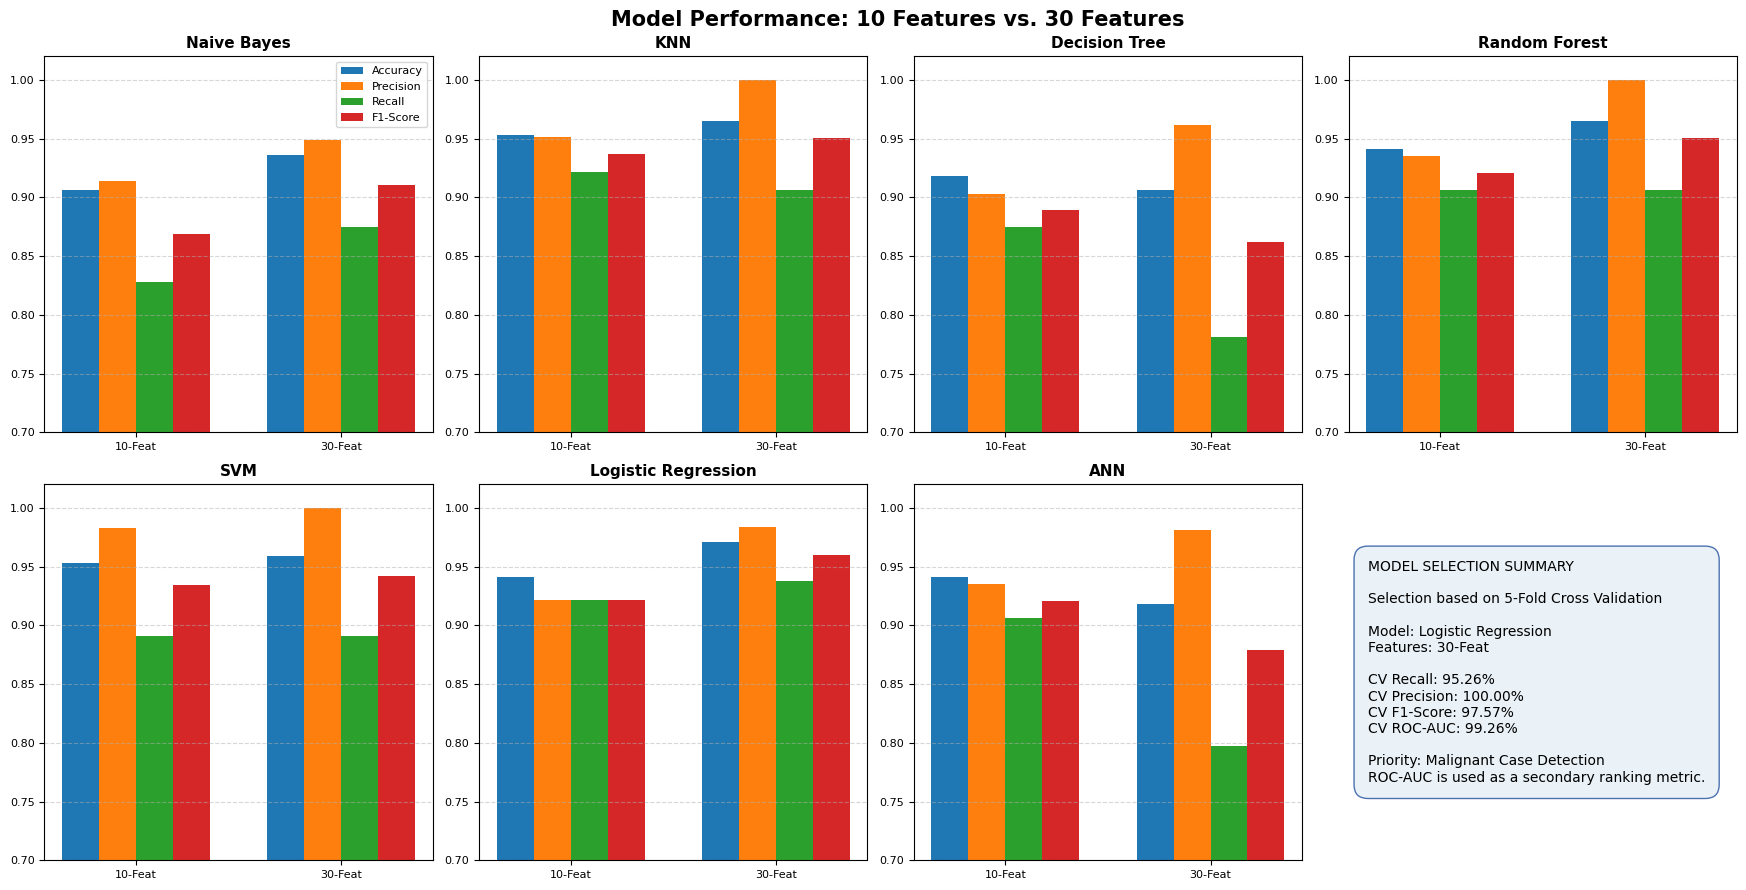

,Model,Feature Set,CV Recall,CV Precision,CV F1,CV ROC-AUC,CV Recall Std
11,Logistic Regression,30-Feat,95.26%,100.00%,97.57%,99.26%,1.67%
9,SVM,30-Feat,94.55%,97.87%,96.15%,99.29%,4.17%
12,ANN,10-Feat,92.55%,89.25%,90.58%,98.30%,5.00%
2,KNN,10-Feat,91.86%,93.48%,92.54%,96.92%,2.83%
7,Random Forest,30-Feat,91.82%,92.59%,91.91%,98.34%,6.01%
6,Random Forest,10-Feat,91.20%,90.48%,90.43%,97.78%,5.06%
4,Decision Tree,10-Feat,90.55%,88.88%,89.51%,92.03%,2.47%
3,KNN,30-Feat,90.46%,98.51%,94.25%,98.38%,5.15%
1,Naive Bayes,30-Feat,89.79%,91.19%,90.42%,98.57%,5.83%
10,Logistic Regression,10-Feat,88.51%,93.33%,90.70%,98.54%,3.52%


In [ ]:

# Configure subplot layout
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 9))
axes = axes.ravel()

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1']
x_labels = ['10-Feat', '30-Feat']
x_indices = np.arange(len(x_labels))
width = 0.18

# Plot performance of all 7 models
for idx, model_name in enumerate(models.keys()):

    ax = axes[idx]
    model_data = df_results[df_results['Model'] == model_name].iloc[0]

    acc_vals = [
        model_data['10-Feat Accuracy'],
        model_data['30-Feat Accuracy']
    ]

    prec_vals = [
        model_data['10-Feat Precision'],
        model_data['30-Feat Precision']
    ]

    rec_vals = [
        model_data['10-Feat Recall'],
        model_data['30-Feat Recall']
    ]

    f1_vals = [
        model_data['10-Feat F1'],
        model_data['30-Feat F1']
    ]

    ax.bar(x_indices - 1.5 * width, acc_vals, width, label='Accuracy')
    ax.bar(x_indices - 0.5 * width, prec_vals, width, label='Precision')
    ax.bar(x_indices + 0.5 * width, rec_vals, width, label='Recall')
    ax.bar(x_indices + 1.5 * width, f1_vals, width, label='F1-Score')

    ax.set_title(model_name, fontsize=11, fontweight='bold')
    ax.set_xticks(x_indices)
    ax.set_xticklabels(x_labels)
    ax.set_ylim(0.70, 1.02)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

    if idx == 0:
        ax.legend(fontsize=8)


# -----------------------------------
# Select the best configuration using Cross Validation
# -----------------------------------

candidates = []

for _, row in df_results.iterrows():

    for feature_set in ['10-Feat', '30-Feat']:

        candidates.append({
            'Model': row['Model'],
            'Feature Set': feature_set,
            'CV Recall': row[f'{feature_set} CV Recall'],
            'CV Precision': row[f'{feature_set} CV Precision'],
            'CV F1': row[f'{feature_set} CV F1'],
            'CV ROC-AUC': row[f'{feature_set} CV ROC-AUC'],
            'CV Recall Std': row[f'{feature_set} CV Recall Std']
        })

df_candidates = pd.DataFrame(candidates)

# Rank by CV Recall, then CV ROC-AUC
best_candidate = df_candidates.sort_values(
    by=['CV Recall', 'CV ROC-AUC'],
    ascending=False
).iloc[0]


# -----------------------------------
# Display selection summary
# -----------------------------------

ax_info = axes[7]
ax_info.axis('off')

info_text = (
    "MODEL SELECTION SUMMARY\n\n"
    "Selection based on 5-Fold Cross Validation\n\n"
    f"Model: {best_candidate['Model']}\n"
    f"Features: {best_candidate['Feature Set']}\n\n"
    f"CV Recall: {best_candidate['CV Recall']:.2%}\n"
    f"CV Precision: {best_candidate['CV Precision']:.2%}\n"
    f"CV F1-Score: {best_candidate['CV F1']:.2%}\n"
    f"CV ROC-AUC: {best_candidate['CV ROC-AUC']:.2%}\n\n"
    "Priority: Malignant Case Detection\n"
    "ROC-AUC is used as a secondary ranking metric."
)

ax_info.text(
    0.05, 0.5, info_text,
    transform=ax_info.transAxes,
    fontsize=10,
    va='center',
    ha='left',
    bbox=dict(
        boxstyle='round,pad=1',
        facecolor='#EAF2F8',
        edgecolor='#4C72B0'
    )
)

plt.suptitle(
    'Model Performance: 10 Features vs. 30 Features',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


# Display all configurations ranked by Cross Validation Recall
display(
    df_candidates.sort_values(
        by=['CV Recall', 'CV ROC-AUC'],
        ascending=False
    ).style.format({
        col: '{:.2%}'
        for col in [
            'CV Recall', 'CV Precision', 'CV F1',
            'CV ROC-AUC', 'CV Recall Std'
        ]
    })
)


### Step 7: Confusion Matrices & Overfitting Analysis
Let's evaluate the Confusion Matrices for both **Logistic Regression** and **KNN** on the 30-feature dataset, and compare training accuracies vs. test accuracies to diagnose potential overfitting.

OVERFITTING ANALYSIS (30 Features)

Logistic Regression -> Train Accuracy: 98.74%, Test Accuracy: 97.08%
KNN                 -> Train Accuracy: 97.24%, Test Accuracy: 96.49%


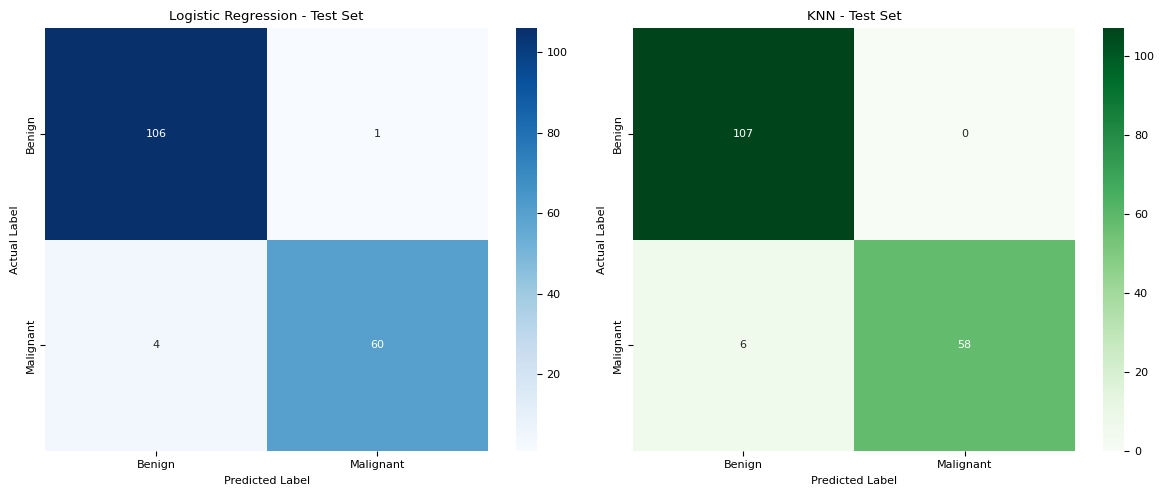

In [ ]:

# Retrieve trained models using the 30-feature configuration
log_reg = trained_models['Logistic Regression']['30 Features']
knn = trained_models['KNN']['30 Features']

# -----------------------------------
# Logistic Regression predictions
# -----------------------------------

y_train_pred_lr = log_reg.predict(X_train_all)
y_test_pred_lr = log_reg.predict(X_test_all)

train_acc_lr = accuracy_score(y_train, y_train_pred_lr)
test_acc_lr = accuracy_score(y_test, y_test_pred_lr)

# -----------------------------------
# KNN predictions
# -----------------------------------

y_train_pred_knn = knn.predict(X_train_all)
y_test_pred_knn = knn.predict(X_test_all)

train_acc_knn = accuracy_score(y_train, y_train_pred_knn)
test_acc_knn = accuracy_score(y_test, y_test_pred_knn)

# -----------------------------------
# Compare training and testing accuracy
# -----------------------------------

print("OVERFITTING ANALYSIS (30 Features)\n")

print(
    f"Logistic Regression -> "
    f"Train Accuracy: {train_acc_lr:.2%}, "
    f"Test Accuracy: {test_acc_lr:.2%}"
)

print(
    f"KNN                 -> "
    f"Train Accuracy: {train_acc_knn:.2%}, "
    f"Test Accuracy: {test_acc_knn:.2%}"
)

# -----------------------------------
# Confusion Matrices
# -----------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_lr = confusion_matrix(y_test, y_test_pred_lr)
cm_knn = confusion_matrix(y_test, y_test_pred_knn)

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0],
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

axes[0].set_title('Logistic Regression - Test Set')
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1],
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

axes[1].set_title('KNN - Test Set')
axes[1].set_ylabel('Actual Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()



### Overfitting Analysis

The difference between training and testing accuracy provides an initial indication of how well a model generalizes to unseen data.

1. **Good Generalization:** When training and testing accuracy are close, the model shows no strong indication of overfitting.

2. **Potential Overfitting:** When training accuracy is considerably higher than testing accuracy, the model may have learned patterns specific to the training data.

3. **Further Evaluation:** A small difference between training and testing accuracy does not prove that a model is completely free of overfitting. Cross-validation results should also be considered.

In this experiment, Logistic Regression and KNN are evaluated using the 30-feature configuration. Their training and testing accuracy values, together with the 5-fold cross-validation results, provide a more reliable overview of their generalization performance.


In [ ]:

# Final evaluation of the selected model

best_model = trained_models['Logistic Regression']['30 Features']

y_pred = best_model.predict(X_test_all)

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Benign', 'Malignant']
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.98       107
   Malignant       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171

Confusion Matrix:
[[106   1]
 [  4  60]]


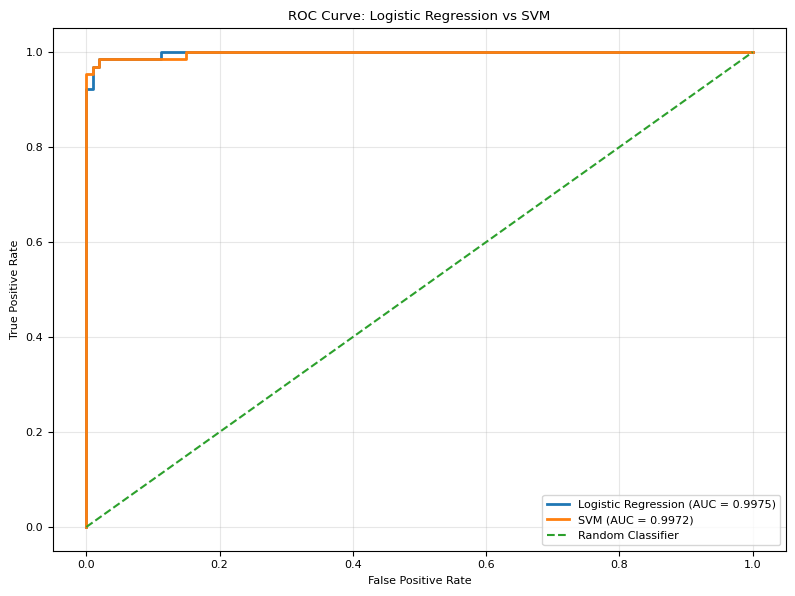

In [ ]:

from sklearn.metrics import roc_curve, auc

# Select trained models
log_reg = trained_models['Logistic Regression']['30 Features']
svm = trained_models['SVM']['30 Features']

# Get prediction probabilities
lr_probs = log_reg.predict_proba(X_test_all)[:, 1]
svm_probs = svm.predict_proba(X_test_all)[:, 1]

# Calculate ROC curves
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
svm_fpr, svm_tpr, _ = roc_curve(y_test, svm_probs)

# Calculate AUC
lr_auc = auc(lr_fpr, lr_tpr)
svm_auc = auc(svm_fpr, svm_tpr)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    lr_fpr, lr_tpr,
    label=f'Logistic Regression (AUC = {lr_auc:.4f})',
    linewidth=2
)

plt.plot(
    svm_fpr, svm_tpr,
    label=f'SVM (AUC = {svm_auc:.4f})',
    linewidth=2
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Logistic Regression vs SVM')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
